# M4 — Grad-CAM sur les **11 mêmes radiographies** qu’E4

**But :** comparer les cartes d'attention des modèles **E4 binaire** et **M4 multiclasses (phase 2)** sur **exactement les mêmes 11 images de validation**, sans réentraînement ni recours au test.

- **Sélection figée** : CSV produit par le notebook E4 (`E4_interpretabilite_GradCAM/E4_GradCAM_selection_validation.csv`). **Ne pas tirer un nouvel échantillon aléatoire**.
- **3 TP E4, 3 FN E4, 3 FP E4, 2 TN E4** ; ces étiquettes décrivent **E4**, pas nécessairement M4.
- **M4** prédit 4 classes : on explique spécifiquement sa **probabilité softmax COVID** avec Grad-CAM sur `block5_conv3`.
- **Décision M4 de référence : argmax**, comme dans nos métriques de validation. Le CSV conserve aussi le score P(COVID) et la prédiction de M4.
- **Contrôles** : correspondance exacte des fichiers sélectionnés, cohérence des prédictions du chemin Grad-CAM avec M4, export des 11 figures et d'un CSV comparatif.

Les images sont prises sur le jeu **validation**. Les cartes sont exploratoires et **ne prouvent pas** la fiabilité clinique ou la généralisation externe.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil, time, json, zipfile
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.models import load_model

PROJECT_DIR = Path('/content/drive/MyDrive/Apprentissage/DS/projet')
DATASET_ROOT = Path('/content/COVID-19_Radiography_Dataset')
DRIVE_DATASET_ROOT = PROJECT_DIR / 'COVID-19_Radiography_Dataset'
E4_DIR = PROJECT_DIR / 'E4_interpretabilite_GradCAM'
E4_SELECTION_CSV = E4_DIR / 'E4_GradCAM_selection_validation.csv'
M4_CHECKPOINT = PROJECT_DIR / 'M4_finetuning' / 'M4_FT2_B5_LR1e-6_best.keras'
OUTPUT_DIR = PROJECT_DIR / 'M4_interpretabilite_GradCAM_comparaison_E4'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Si runtime Colab neuf : décommenter la copie locale (longue mais nécessaire).
if not DATASET_ROOT.exists():
     t = time.perf_counter()
     shutil.copytree(DRIVE_DATASET_ROOT, DATASET_ROOT)
     print('Copie locale :', round((time.perf_counter()-t)/60, 1), 'min')

assert DATASET_ROOT.is_dir(), 'Dataset local absent : décommenter la copie.'
assert E4_SELECTION_CSV.is_file(), f'Sélection E4 absente : {E4_SELECTION_CSV}'
assert M4_CHECKPOINT.is_file(), f'Checkpoint M4 phase 2 absent : {M4_CHECKPOINT}'
print('Sélection E4 :', E4_SELECTION_CSV)
print('Checkpoint M4 :', M4_CHECKPOINT)

Mounted at /content/drive
Copie locale : 18.8 min
Sélection E4 : /content/drive/MyDrive/Apprentissage/DS/projet/E4_interpretabilite_GradCAM/E4_GradCAM_selection_validation.csv
Checkpoint M4 : /content/drive/MyDrive/Apprentissage/DS/projet/M4_finetuning/M4_FT2_B5_LR1e-6_best.keras


## 1 — Reprendre exactement les 11 indices E4

On utilise les **indices dans `validation.csv`** sauvegardés par E4, dans le **même ordre**. La colonne `groupe` du CSV est le groupe E4 ; les résultats M4 seront calculés indépendamment. Une vérification du chemin relatif empêche les comparaisons accidentelles entre deux images différentes.

In [2]:
val_df = pd.read_csv(PROJECT_DIR / 'validation.csv')
selection = pd.read_csv(E4_SELECTION_CSV)

def local_filepath(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin CSV inattendu : {original}')
    return str(DATASET_ROOT / normalized.split(marker,1)[1])

def relative_dataset_path(original):
    normalized = str(original).replace('\\', '/')
    marker = 'COVID-19_Radiography_Dataset/'
    if marker not in normalized:
        raise ValueError(f'Chemin inattendu : {original}')
    return normalized.split(marker,1)[1]

val_df['filepath'] = val_df['filepath'].map(local_filepath)
assert len(val_df) == 3387, 'Validation inattendue.'
assert len(selection) == 11, f'Attendu 11 images E4, trouvé {len(selection)}.'
assert selection['index_validation'].is_unique, 'Indices E4 dupliqués.'
assert selection['index_validation'].between(0, len(val_df)-1).all()
assert selection['groupe'].value_counts().to_dict() == {'TP':3,'FN':3,'FP':3,'TN':2}

for r in selection.itertuples(index=False):
    actual = val_df.iloc[int(r.index_validation)]
    assert relative_dataset_path(r.filepath) == relative_dataset_path(actual['filepath']), (r.index_validation, r.filepath)
    assert Path(actual['filepath']).is_file(), actual['filepath']
    assert int(r.vrai) == int(str(actual['class']).strip().upper() == 'COVID'), 'Label E4/M4 incohérent.'

print('11 images E4 retrouvées dans validation.csv, ordre et labels vérifiés.')
print(selection[['groupe','index_validation','vrai','proba_COVID']].to_string(index=False))

11 images E4 retrouvées dans validation.csv, ordre et labels vérifiés.
groupe  index_validation  vrai  proba_COVID
    TP              2278     1     0.999233
    TP               321     1     0.999693
    TP              2685     1     0.565868
    FN               356     1     0.004975
    FN              2601     1     0.001841
    FN              2603     1     0.055080
    FP              1095     0     0.957430
    FP              3138     0     0.489807
    FP              2365     0     0.938141
    TN              1740     0     0.000006
    TN              2645     0     0.000003


## 2 — Charger M4 et identifier la classe COVID

Le mapping des classes est reconstruit comme dans le notebook M4 d'entraînement : tri des libellés de `train.csv`. **Ne jamais supposer que COVID est l'indice 1.**

In [3]:
def load_compatible_checkpoint(path):
    try:
        return load_model(path, compile=False)
    except (TypeError, ValueError) as exc:
        if 'input_axes' not in str(exc) and 'output_axes' not in str(exc):
            raise
        print('Correctif compatibilité GlorotUniform…')
        patched = Path('/content/M4_gradcam_compatible.keras')
        def clean(obj):
            if isinstance(obj,dict):
                if obj.get('class_name') == 'GlorotUniform':
                    obj.get('config',{}).pop('input_axes',None)
                    obj.get('config',{}).pop('output_axes',None)
                for v in obj.values(): clean(v)
            elif isinstance(obj,list):
                for v in obj: clean(v)
        with zipfile.ZipFile(path) as src:
            config=json.loads(src.read('config.json'))
            clean(config)
            with zipfile.ZipFile(patched,'w') as dst:
                for member in src.infolist():
                    payload=json.dumps(config).encode() if member.filename=='config.json' else src.read(member.filename)
                    dst.writestr(member,payload)
        return load_model(patched,compile=False)

classes = sorted(pd.read_csv(PROJECT_DIR/'train.csv')['class'].dropna().astype(str).unique().tolist())
assert len(classes)==4, f'M4 doit avoir 4 classes : {classes}'
covid_matches=[i for i,c in enumerate(classes) if c.strip().upper()=='COVID']
assert len(covid_matches)==1, f'COVID introuvable : {classes}'
covid_idx=covid_matches[0]
model=load_compatible_checkpoint(M4_CHECKPOINT)
model.summary()
assert model.output_shape[-1]==4, f'M4 attendu 4 sorties : {model.output_shape}'
print('Classes M4 :', dict(enumerate(classes)), '| index COVID :',covid_idx)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 7,145,604 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

Classes M4 : {0: 'COVID', 1: 'Lung_Opacity', 2: 'Normal', 3: 'Viral Pneumonia'} | index COVID : 0


## 3 — Prédictions M4 sur les 11 images, sans réévaluer tout le dataset

Même prétraitement VGG16 que pour E4 : **RGB 224 × 224 + `preprocess_input`**, sans normalisation `1/255`. On conserve aussi les probabilités E4 sauvegardées pour faciliter la comparaison.

In [4]:
def read_image(filepath):
    rgb=img_to_array(load_img(filepath,target_size=(224,224),color_mode='rgb')).astype('uint8')
    x=preprocess_input(rgb.astype('float32').copy())
    return rgb,x

images=[]; inputs=[]
for r in selection.itertuples(index=False):
    rgb,x=read_image(val_df.iloc[int(r.index_validation)]['filepath'])
    images.append(rgb); inputs.append(x)
inputs=np.stack(inputs).astype('float32')
probs=np.asarray(model.predict(inputs,verbose=0))
assert probs.shape==(11,4)
assert np.allclose(probs.sum(axis=1),1,atol=1e-3), 'Sortie M4 non normalisée : vérifier softmax.'
m4_idx=probs.argmax(axis=1)
m4_label=[classes[i] for i in m4_idx]
print('Prédictions M4 :',list(zip(selection['groupe'],m4_label,np.round(probs[:,covid_idx],3))))

Prédictions M4 : [('TP', 'COVID', np.float32(0.99)), ('TP', 'COVID', np.float32(1.0)), ('TP', 'COVID', np.float32(0.965)), ('FN', 'Lung_Opacity', np.float32(0.154)), ('FN', 'Lung_Opacity', np.float32(0.003)), ('FN', 'COVID', np.float32(0.546)), ('FP', 'COVID', np.float32(0.953)), ('FP', 'Normal', np.float32(0.38)), ('FP', 'COVID', np.float32(0.959)), ('TN', 'Normal', np.float32(0.0)), ('TN', 'Lung_Opacity', np.float32(0.0))]


## 4 — Grad-CAM de M4 : score COVID softmax

Comme pour E4, les activations de `block5_conv3` sont combinées avec les gradients du **score COVID**. **Différence importante** : M4 a quatre sorties ; on choisit la colonne `covid_idx` plutôt que `scores[:,0]` ou `argmax`. Le contrôle ci-dessous vérifie que le chemin reconstruit produit les mêmes 4 probabilités que M4.

In [5]:
base=next((layer for layer in model.layers if isinstance(layer,tf.keras.Model)
           and any(l.name=='block5_conv3' for l in layer.layers)),None)
assert base is not None, 'VGG16 imbriqué introuvable : vérifier model.summary().'
last_conv=base.get_layer('block5_conv3')
extractor=tf.keras.Model(inputs=base.inputs,outputs=[last_conv.output,base.output])
base_index=model.layers.index(base)
head_layers=[l for l in model.layers[base_index+1:] if not isinstance(l,tf.keras.layers.InputLayer)]
print('Grad-CAM :',last_conv.name,'| tête M4 :',[l.name for l in head_layers])

def forward_gradcam(x):
    acts,z=extractor(x,training=False)
    for layer in head_layers:
        z=layer(z,training=False)
    return acts,z

_,reconstructed=forward_gradcam(tf.convert_to_tensor(inputs[:2]))
original=model(tf.convert_to_tensor(inputs[:2]),training=False)
diff=float(tf.reduce_max(tf.abs(reconstructed-original)).numpy())
print('Différence maximale (doit être ~0) :',diff)
assert diff<1e-4, 'Chemin Grad-CAM incohérent avec M4 : STOP.'

def make_gradcam(preprocessed):
    x=tf.convert_to_tensor(preprocessed[None,...],dtype=tf.float32)
    with tf.GradientTape() as tape:
        acts,scores=forward_gradcam(x)
        covid_score=scores[:,covid_idx]
    grads=tape.gradient(covid_score,acts)
    assert grads is not None, 'Gradients absents.'
    weights=tf.reduce_mean(grads,axis=(0,1,2))
    heatmap=tf.reduce_sum(acts[0]*weights,axis=-1)
    heatmap=tf.nn.relu(heatmap)
    heatmap=heatmap/(tf.reduce_max(heatmap)+tf.keras.backend.epsilon())
    return heatmap.numpy()

Grad-CAM : block5_conv3 | tête M4 : ['global_average_pooling2d', 'dense', 'dropout', 'dense_1']
Différence maximale (doit être ~0) : 0.0


## 5 — Générer les 11 figures M4 **et** les comparaisons E4/M4

Chaque image reçoit : radiographie originale, carte M4 et superposition M4. Si la figure E4 est disponible sur Drive, on crée également une figure **côte à côte** montrant les deux superpositions sur **la même radiographie**. Les fichiers sont conservés dans `M4_interpretabilite_GradCAM_comparaison_E4`.

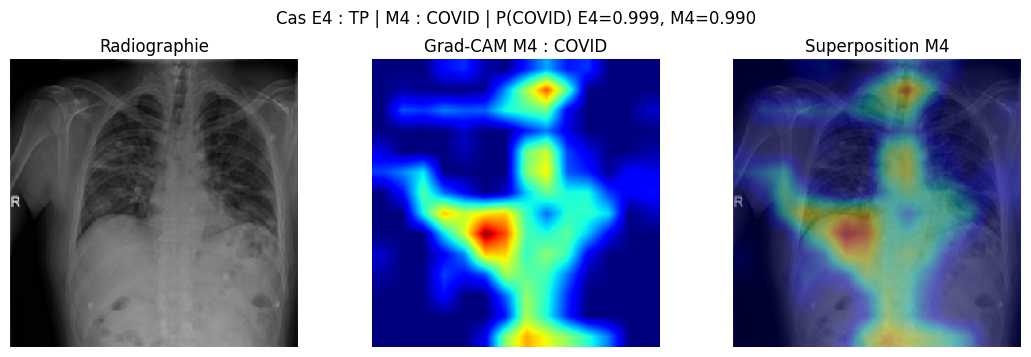

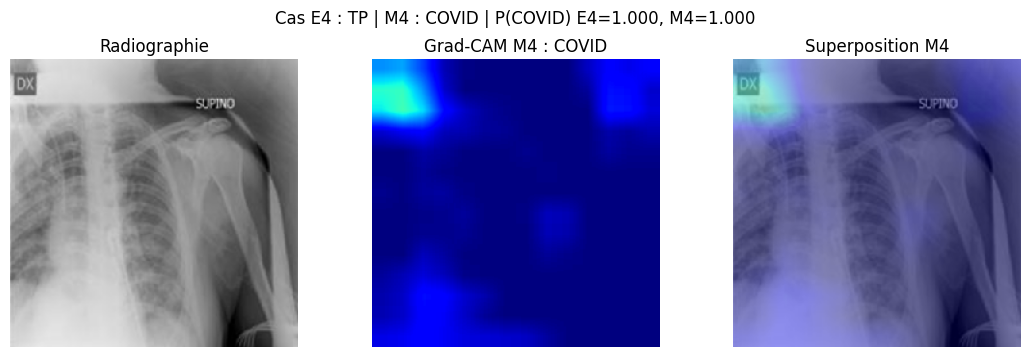

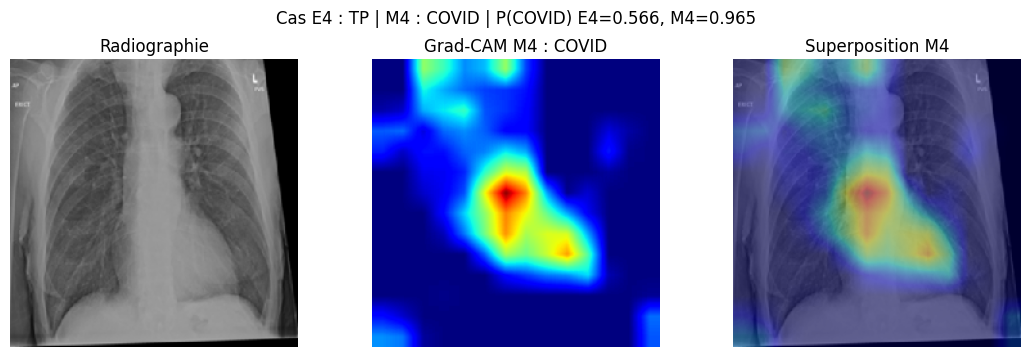

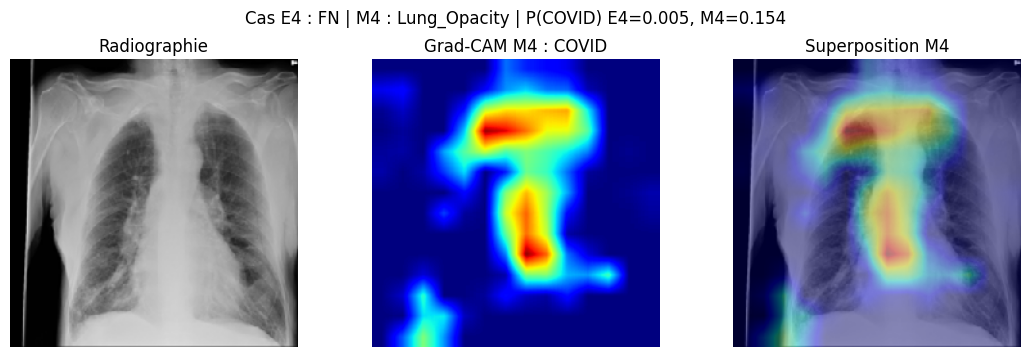

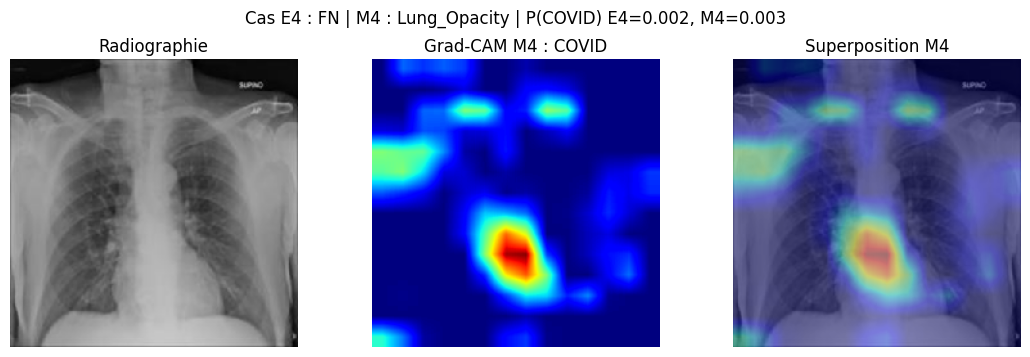

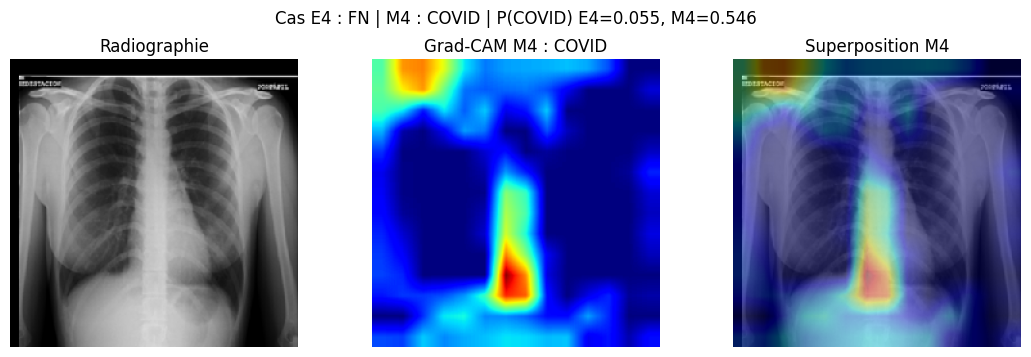

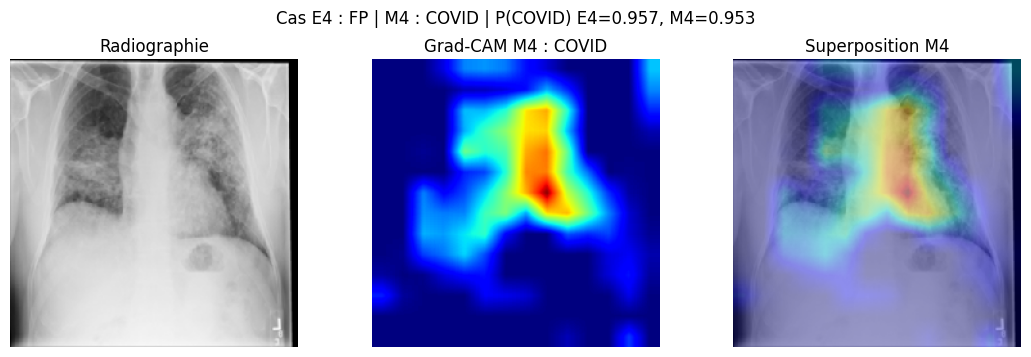

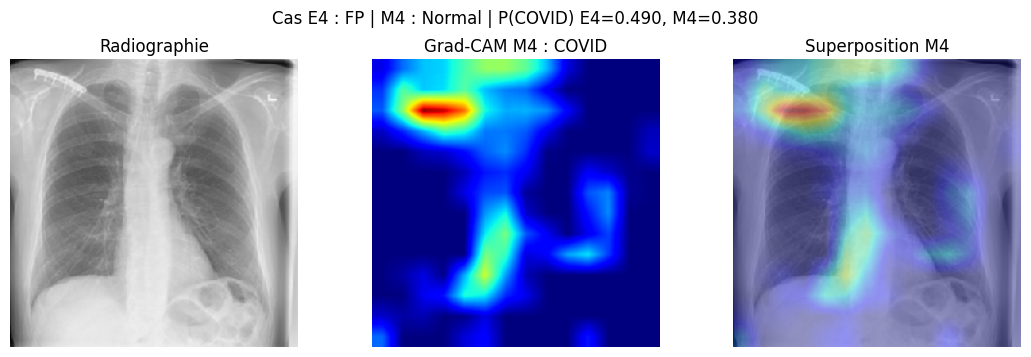

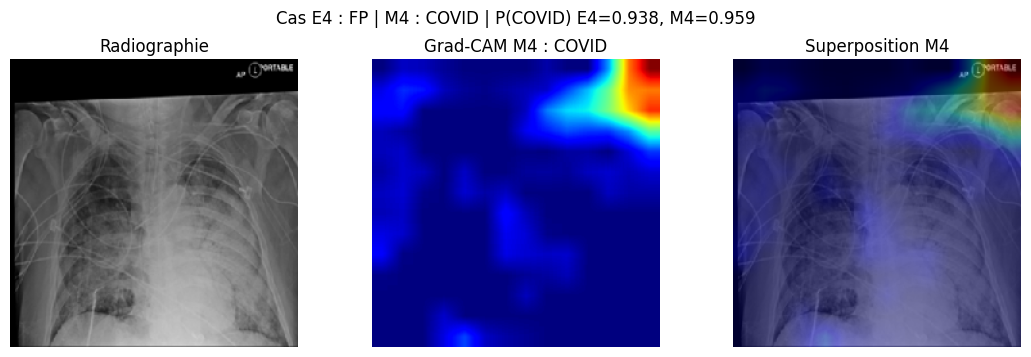

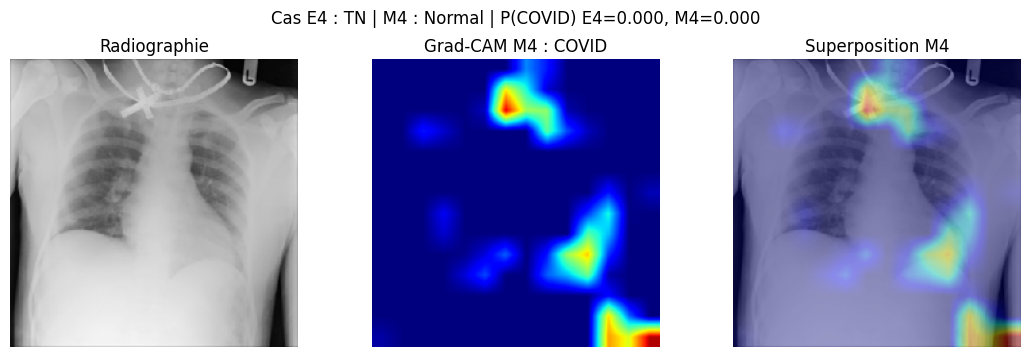

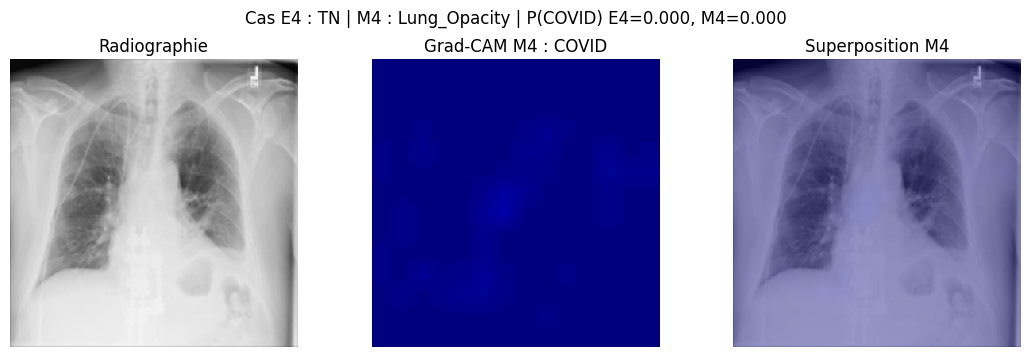

Figures générées : 11 | accord E4/M4 : 9 /11


,groupe_E4,index_validation,vrai_COVID,P_COVID_E4,P_COVID_M4,prediction_M4,accord_E4_M4
0,TP,2278,1,0.999233,9.896326e-01,COVID,True
1,TP,321,1,0.999693,9.999999e-01,COVID,True
2,TP,2685,1,0.565868,9.647704e-01,COVID,True
3,FN,356,1,0.004975,1.536612e-01,Lung_Opacity,True
4,FN,2601,1,0.001841,3.035555e-03,Lung_Opacity,True
5,FN,2603,1,0.055080,5.459801e-01,COVID,False
6,FP,1095,0,0.957430,9.533154e-01,COVID,True
7,FP,3138,0,0.489807,3.800143e-01,Normal,False
8,FP,2365,0,0.938141,9.591679e-01,COVID,True
9,TN,1740,0,0.000006,3.940399e-05,Normal,True


Résultats sauvegardés : /content/drive/MyDrive/Apprentissage/DS/projet/M4_interpretabilite_GradCAM_comparaison_E4


In [6]:
rows=[]
for j,r in enumerate(selection.itertuples(index=False)):
    rgb=images[j]; heat=make_gradcam(inputs[j]); idx=int(r.index_validation)
    heat_resized=np.asarray(Image.fromarray(np.uint8(255*heat)).resize((224,224),resample=Image.Resampling.BILINEAR))/255.
    fig,ax=plt.subplots(1,3,figsize=(11,3.6))
    ax[0].imshow(rgb);ax[0].set_title('Radiographie')
    ax[1].imshow(heat_resized,cmap='jet',vmin=0,vmax=1);ax[1].set_title('Grad-CAM M4 : COVID')
    ax[2].imshow(rgb);ax[2].imshow(heat_resized,cmap='jet',alpha=.38,vmin=0,vmax=1);ax[2].set_title('Superposition M4')
    for a in ax:a.axis('off')
    fig.suptitle(f'Cas E4 : {r.groupe} | M4 : {m4_label[j]} | P(COVID) E4={r.proba_COVID:.3f}, M4={probs[j,covid_idx]:.3f}')
    fig.tight_layout()
    fname=f'M4_GradCAM_E4{r.groupe}_index{idx:04d}.png'
    fig.savefig(OUTPUT_DIR/fname,dpi=170,bbox_inches='tight');plt.show();plt.close(fig)

    # Même image, cartes des deux modèles côte à côte.
    e4_fig=E4_DIR / str(r.figure)
    if e4_fig.is_file():
        e4_png=np.asarray(Image.open(e4_fig).convert('RGB'))
        m4_png=np.asarray(Image.open(OUTPUT_DIR/fname).convert('RGB'))
        fig2,ax2=plt.subplots(1,2,figsize=(15,5))
        ax2[0].imshow(e4_png);ax2[0].set_title(f'E4 — cas {r.groupe}')
        ax2[1].imshow(m4_png);ax2[1].set_title(f'M4 — prédiction {m4_label[j]}')
        for a in ax2:a.axis('off')
        fig2.tight_layout()
        fig2.savefig(OUTPUT_DIR/f'COMPARAISON_E4_M4_index{idx:04d}.png',dpi=150,bbox_inches='tight')
        plt.close(fig2)
    else:
        print('Figure E4 non trouvée (comparaison côte à côte ignorée) :',e4_fig)

    rows.append({'groupe_E4':r.groupe,'index_validation':idx,
                 'filepath':val_df.iloc[idx]['filepath'],
                 'vrai_COVID':int(r.vrai),
                 'P_COVID_E4':float(r.proba_COVID),
                 'prediction_COVID_E4':int(r.prediction),
                 'P_COVID_M4':float(probs[j,covid_idx]),
                 'prediction_M4':m4_label[j],
                 'prediction_COVID_M4_argmax':int(m4_idx[j]==covid_idx),
                 'accord_E4_M4':bool(int(r.prediction)==int(m4_idx[j]==covid_idx)),
                 'figure_M4':fname,'figure_E4':str(r.figure)})

comparison=pd.DataFrame(rows)
comparison.to_csv(OUTPUT_DIR/'comparaison_E4_M4_memes_11_images.csv',index=False)
print('Figures générées :',len(rows),'| accord E4/M4 :',comparison['accord_E4_M4'].sum(),'/11')
display(comparison[['groupe_E4','index_validation','vrai_COVID','P_COVID_E4','P_COVID_M4','prediction_M4','accord_E4_M4']])
print('Résultats sauvegardés :',OUTPUT_DIR)

## 6 — Pour le rapport (après inspection visuelle)

Comparer les **mêmes images** pour les deux modèles :

1. Les cartes M4 sont-elles davantage concentrées sur les **champs pulmonaires** que celles d'E4 ? Attention à ne pas interpréter toute zone chaude comme une lésion.
2. Pour les **FN et FP d'E4**, M4 est-il d'accord avec E4 ou corrige-t-il sa prédiction ?
3. Les deux modèles semblent-ils parfois sensibles aux **bordures, inscriptions, cadrages ou autres artefacts** ?
4. Les différences de cartes sont-elles **qualitatives** seulement ? Grad-CAM ne quantifie pas la robustesse hors distribution.

**Point de méthode :** les catégories TP/FN/FP/TN sont celles d'E4 ; M4 peut changer de catégorie pour la même image. Le seuil 0,35 d'E4 n'est pas un seuil M4. Ici, la prédiction M4 est son **argmax initial**, et Grad-CAM explique le **score softmax COVID**.

**À ne pas conclure :** « M4 généralise mieux » sur la seule base de cartes plus pulmonaires. La généralisation nécessite une évaluation externe indépendante. Le jeu de **test reste intact**.